In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('Social_Network_Ads.csv')

In [4]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [5]:
df.isnull().sum()

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


In [7]:
df.describe()

,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


In [8]:
df.shape

(400, 5)

In [9]:
df.head(1)

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0


In [10]:
df['Gender'].value_counts()

Gender
Female    204
Male      196
Name: count, dtype: int64

## So there are more females involved than males in the dataset

<Axes: ylabel='count'>

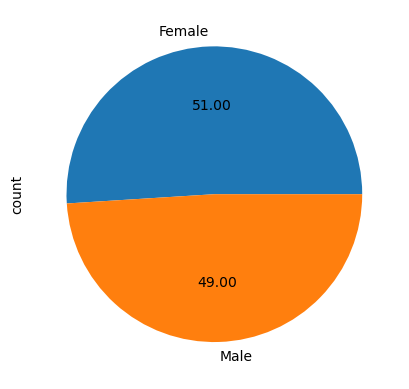

In [11]:
df['Gender'].value_counts().plot(kind='pie', autopct='%0.2f')

In [12]:
df.head(1)

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0


In [13]:
mask_male=df['Gender']=='Male'
mask_female=df['Gender']=='Female'

In [14]:
df[mask_male].sample(3)

,User ID,Gender,Age,EstimatedSalary,Purchased
398,15755018,Male,36,33000,0
189,15715160,Male,28,32000,0
117,15591433,Male,36,52000,0


In [15]:
df[mask_female].sample(3)

,User ID,Gender,Age,EstimatedSalary,Purchased
175,15614420,Female,23,28000,0
84,15798659,Female,30,62000,0
295,15725794,Female,36,63000,0


In [16]:
df[mask_male]['EstimatedSalary'].mean()

67642.85714285714

In [17]:
df[mask_female]['EstimatedSalary'].mean()

71759.80392156863

## The mean salary of the Females was a bit higher than the males

In [18]:
df[mask_male]['Age'].mean()

36.86734693877551

In [19]:
df[mask_female]['Age'].mean()

38.411764705882355

In [20]:
df[mask_male]['Age'].median()

36.5

In [21]:
df[mask_female]['Age'].median()

37.5

<Axes: xlabel='Age', ylabel='EstimatedSalary'>

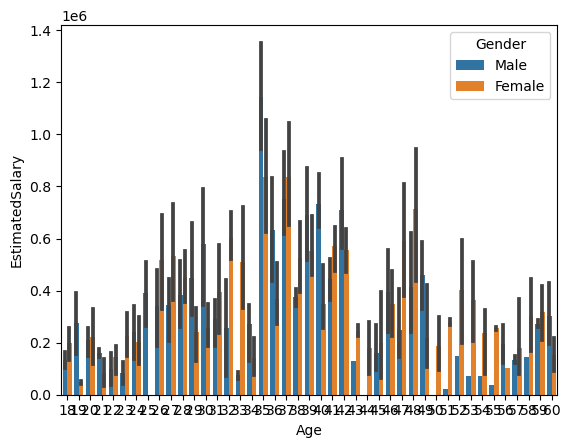

In [22]:
sns.barplot(y='EstimatedSalary',x = 'Age', hue='Gender',data = df,estimator = sum)

<Axes: xlabel='Age', ylabel='EstimatedSalary'>

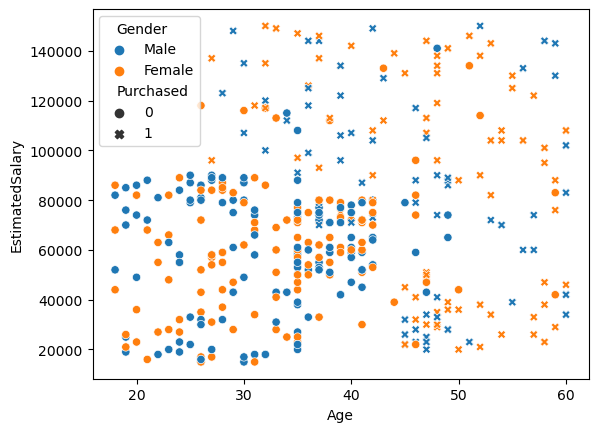

In [23]:
sns.scatterplot(x='Age', y = 'EstimatedSalary', data = df, hue='Gender', style = 'Purchased')

## From Age 20 to 35(roughly), people with low to even medium Salary didn't purcharse the product. 
## However, Aged people with even low salaries bought the product

In [24]:
df.head(2)

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0


In [25]:
new = df.iloc[:, 2:]

In [26]:
new.head(2)

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0


In [27]:
df.drop(columns=['User ID', 'Gender'], inplace = True )

In [28]:
df.head(2)

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0


## Standarization

In [29]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.drop('Purchased', axis = 1), df['Purchased'], test_size=0.3, random_state = 0)

In [30]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [31]:
X_train_scaled.shape

(280, 2)

In [32]:
X_train_scaled

array([[-1.1631724 , -1.5849703 ],
       [ 2.17018137,  0.93098672],
       [ 0.0133054 ,  1.22017719],
       [ 0.20938504,  1.07558195],
       [ 0.40546467, -0.48604654],
       [-0.28081405, -0.31253226],
       [ 0.99370357, -0.8330751 ],
       [ 0.99370357,  1.8563962 ],
       [ 0.0133054 ,  1.24909623],
       [-0.86905295,  2.26126285],
       [-1.1631724 , -1.5849703 ],
       [ 2.17018137, -0.80415605],
       [-1.35925203, -1.46929411],
       [ 0.40546467,  2.2901819 ],
       [ 0.79762394,  0.75747245],
       [-0.96709276, -0.31253226],
       [ 0.11134522,  0.75747245],
       [-0.96709276,  0.55503912],
       [ 0.30742485,  0.06341534],
       [ 0.69958412, -1.26686079],
       [-0.47689368, -0.0233418 ],
       [-1.7514113 ,  0.3526058 ],
       [-0.67297331,  0.12125343],
       [ 0.40546467,  0.29476771],
       [-0.28081405,  0.06341534],
       [-0.47689368,  2.2901819 ],
       [ 0.20938504,  0.03449629],
       [ 1.28782302,  2.20342476],
       [ 0.79762394,

In [33]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns = X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns = X_test.columns)


In [34]:
X_train_scaled

,Age,EstimatedSalary
0,-1.163172,-1.584970
1,2.170181,0.930987
2,0.013305,1.220177
3,0.209385,1.075582
4,0.405465,-0.486047
...,...,...
275,0.993704,-1.151185
276,-0.869053,-0.775237
277,-0.182774,-0.514966
278,-1.065133,-0.457127


In [35]:
np.round(X_train.describe(), 1)

,Age,EstimatedSalary
count,280.0,280.0
mean,37.9,69807.1
std,10.2,34641.2
min,18.0,15000.0
25%,30.0,43000.0
50%,37.0,70500.0
75%,46.0,88000.0
max,60.0,150000.0


In [36]:
X_train.describe()

,Age,EstimatedSalary
count,280.000000,280.000000
mean,37.864286,69807.142857
std,10.218201,34641.201654
min,18.000000,15000.000000
25%,30.000000,43000.000000
50%,37.000000,70500.000000
75%,46.000000,88000.000000
max,60.000000,150000.000000


In [37]:
np.round(X_train.describe(), 3)

,Age,EstimatedSalary
count,280.000,280.000
mean,37.864,69807.143
std,10.218,34641.202
min,18.000,15000.000
25%,30.000,43000.000
50%,37.000,70500.000
75%,46.000,88000.000
max,60.000,150000.000


In [39]:
np.round(X_train_scaled.describe(), 2)

,Age,EstimatedSalary
count,280.00,280.00
mean,0.00,0.00
std,1.00,1.00
min,-1.95,-1.58
25%,-0.77,-0.78
50%,-0.08,0.02
75%,0.80,0.53
max,2.17,2.32


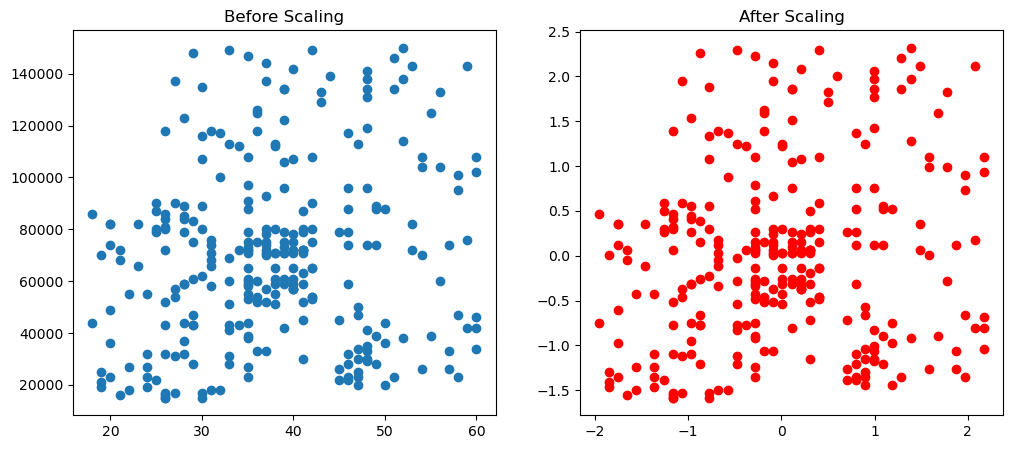

In [44]:
fig, (ax1,ax2) = plt.subplots(ncols=2, figsize = (12,5))
ax1.scatter(X_train['Age'], X_train['EstimatedSalary'])
ax1.set_title("Before Scaling")
ax2.scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'], color = 'red')
ax2.set_title("After Scaling")
plt.show()

C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating ins

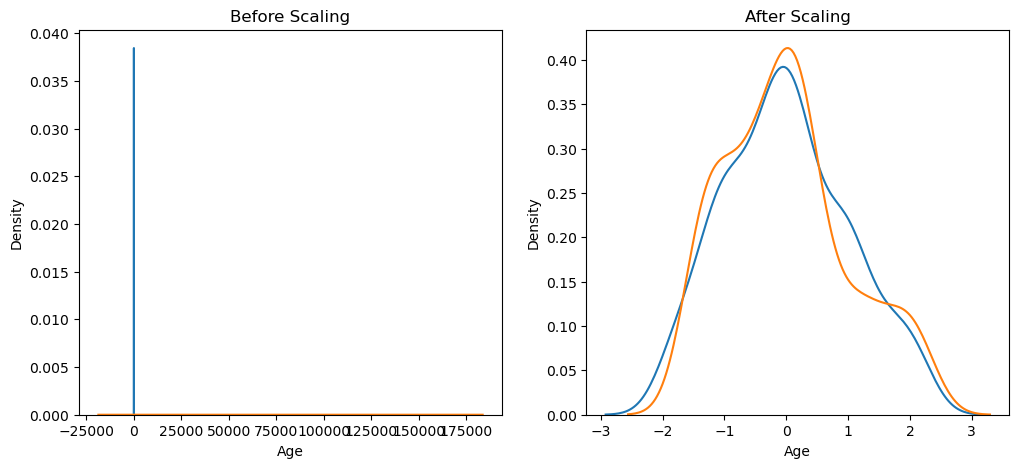

In [48]:
fig, (ax1,ax2) = plt.subplots(ncols = 2, figsize=(12,5))
ax1.set_title("Before Scaling")
ax2.set_title("After Scaling")
sns.kdeplot(X_train['Age'], ax = ax1)
sns.kdeplot(X_train['EstimatedSalary'], ax = ax1)
sns.kdeplot(X_train_scaled['Age'], ax = ax2)
sns.kdeplot(X_train_scaled['EstimatedSalary'], ax = ax2)
plt.show()

C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


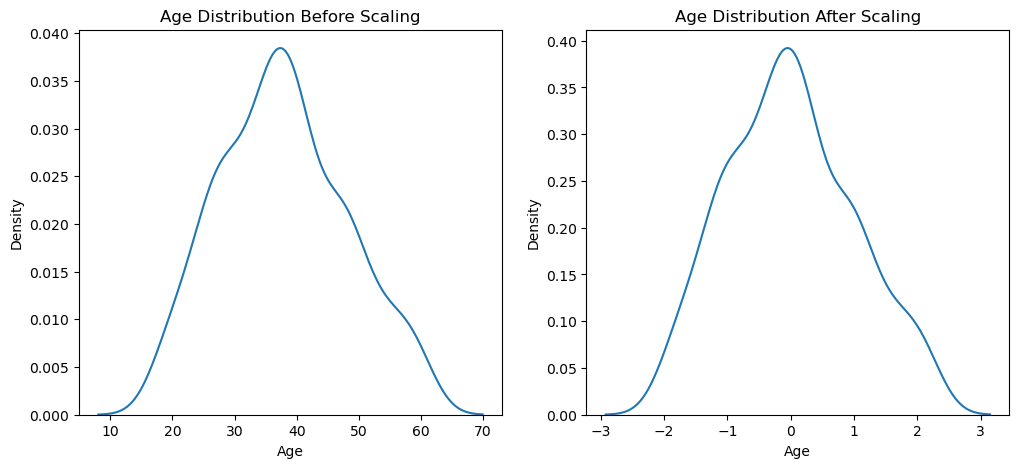

In [52]:
fig, (ax1,ax2) = plt.subplots(ncols = 2, figsize=(12,5))

ax1.set_title('Age Distribution Before Scaling')
ax2.set_title('Age Distribution After Scaling')
sns.kdeplot(X_train['Age'],ax = ax1)
sns.kdeplot(X_train_scaled['Age'], ax = ax2)
plt.show()

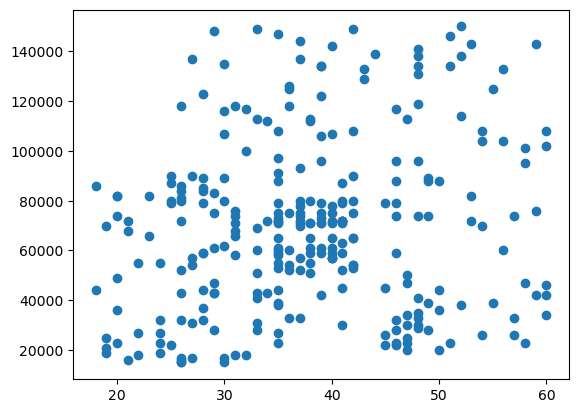

In [54]:
plt.scatter(X_train['Age'], X_train['EstimatedSalary'])

C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


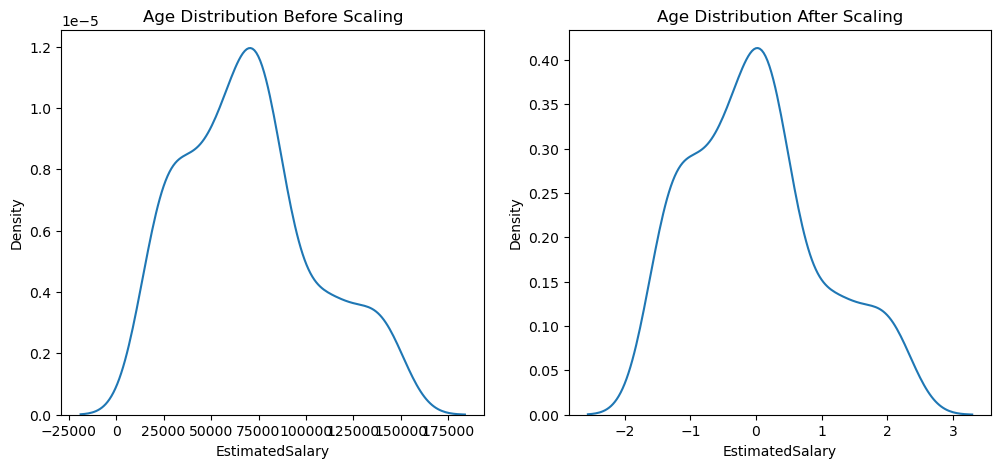

In [55]:
fig, (ax1,ax2) = plt.subplots(ncols = 2, figsize=(12,5))

ax1.set_title('Age Distribution Before Scaling')
ax2.set_title('Age Distribution After Scaling')
sns.kdeplot(X_train['EstimatedSalary'],ax = ax1)
sns.kdeplot(X_train_scaled['EstimatedSalary'], ax = ax2)
plt.show()

In [56]:
from sklearn.linear_model import LogisticRegression

In [57]:
lr = LogisticRegression()

In [58]:
lr_scaled = LogisticRegression()

In [60]:
lr.fit(X_train, y_train)
lr_scaled.fit(X_train_scaled, y_train)

LogisticRegression()

In [61]:
y_pred = lr.predict(X_test)

In [63]:
y_pred_scaled = lr_scaled.predict(X_test_scaled)

In [65]:
type(y_pred)

numpy.ndarray

In [66]:
y_pred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=int64)

In [67]:
y_pred_scaled

array([0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 1, 1, 0, 1, 1], dtype=int64)

In [68]:
from sklearn.metrics import accuracy_score

In [70]:
print("Actual Score : ", accuracy_score(y_test, y_pred))

Actual Score :  0.6583333333333333


In [72]:
print("Actual Score : ", accuracy_score(y_test, y_pred_scaled))

Actual Score :  0.8666666666666667


In [75]:
from sklearn.tree import DecisionTreeClassifier

In [82]:
dt = DecisionTreeClassifier()
dt_scaled = DecisionTreeClassifier()


In [83]:
dt.fit(X_train, y_train)
dt_scaled.fit(X_train_scaled, y_train)

DecisionTreeClassifier()

In [86]:
y_pred = dt.predict(X_test)
y_pred_scaled = dt_scaled.predict(X_test_scaled)

In [87]:
print('Actual : ', accuracy_score(y_test, y_pred_scaled))
print('Scaled : ', accuracy_score(y_test, y_pred_scaled))

Actual :  0.8666666666666667
Scaled :  0.8666666666666667


In [88]:
df.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


In [91]:

# Assuming df is your existing DataFrame
new_data = pd.DataFrame({
    'Age': [5, 90, 95], 
    'EstimatedSalary': [1000, 250000, 350000],
    'Purchased': [0, 1, 1]
})

cf = pd.concat([df, new_data], ignore_index=True)


In [92]:
cf.shape

(403, 3)

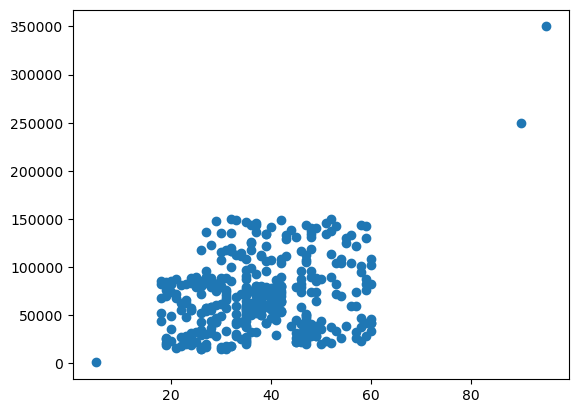

In [93]:
plt.scatter(cf['Age'], cf['EstimatedSalary'])

In [100]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    cf.drop('Purchased', axis =1),
    cf['Purchased'], test_size = 0.3,
    random_state =0)

In [101]:
X_train.shape

(282, 2)

In [102]:
X_test.shape

(121, 2)

In [103]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [104]:
scaler.fit(X_train)
X_trained_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [119]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns = X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns = X_test.columns)

In [120]:
X_train_scaled

,Age,EstimatedSalary
0,-1.163172,-1.584970
1,2.170181,0.930987
2,0.013305,1.220177
3,0.209385,1.075582
4,0.405465,-0.486047
...,...,...
275,0.993704,-1.151185
276,-0.869053,-0.775237
277,-0.182774,-0.514966
278,-1.065133,-0.457127


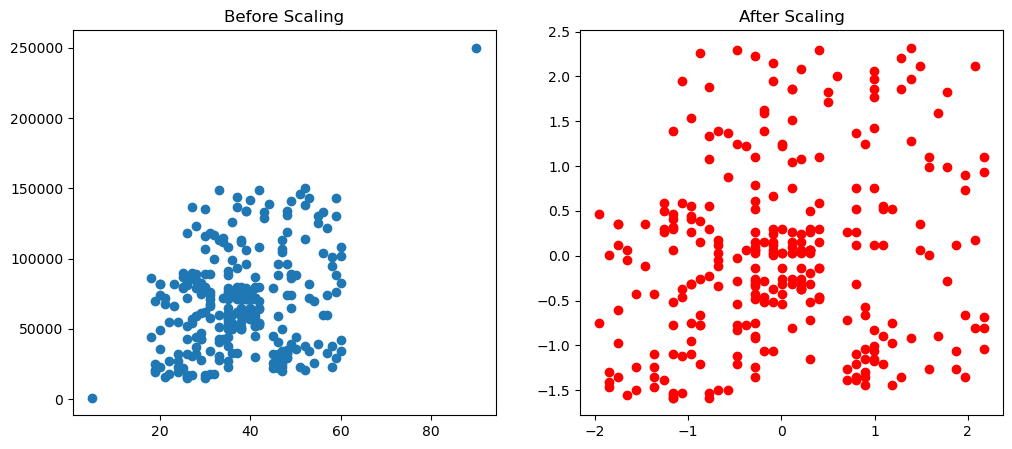

In [122]:
fig, (ax1,ax2) = plt.subplots(ncols = 2, figsize =(12,5))
ax1.set_title("Before Scaling")
ax2.set_title("After Scaling")
ax1.scatter(X_train['Age'], X_train['EstimatedSalary'])
ax2.scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'], color = 'red')

## Normalization

In [124]:
# Types
# 1) Min Max Scaling
# 2) Mean normalization
# 3) Max absolute
# 4) Robust Scaling